In [9]:
# From arb
from pynq import Overlay
import xrfclk
from pynq import PL
import pynq
from pynq.lib import AxiGPIO

# From ADC part
from adc_scope import AdcScope

import xrfdc
import matplotlib.pyplot as plt
%matplotlib inline

# From AWG part
import numpy as np
from rfsoc_awg import *      # AWG, Pulse and the unit helpers ns, us, kHz, MHz, GHz

In [10]:
PL.reset()
xrfclk.set_ref_clks(lmk_freq=245.76, lmx_freq=491.52)   #Programs the oscillators on the board to produce the appropriate clock signals

ol = Overlay("awg_adc.bit") #Load the FPGA bit file 

Window = 0.9993 us  (9824 samples, 614 clock cycles)  [requested 1.0000 us]


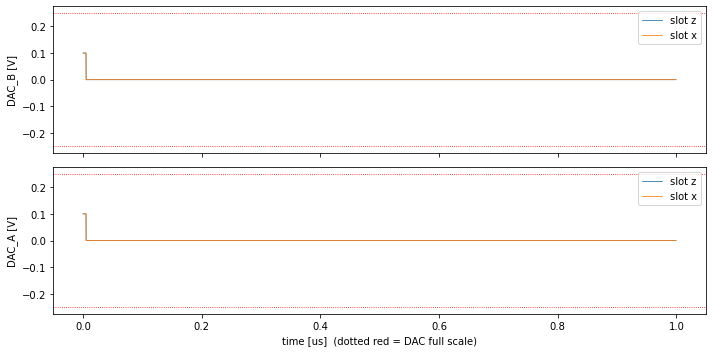

Asserting external reset (low)...
Releasing external reset (high)...
DMA upload took 0.0065 s
Started: ['DAC_A', 'DAC_B']
Stopped.
DMA upload took 0.0114 s
Started: ['DAC_A', 'DAC_B']


In [14]:
## DAC

# Length of ONE waveform slot. It is rounded to a multiple of 1.6276 ns; the real value is printed.
# (Max 26.67 us.)
awg = AWG(window=1 * us, bitfile=ol)
# chirp = 0.1 * np.sin(2 * np.pi * (50 * MHz * awg.t + 0.5 * (20 * MHz / awg.window/4) * awg.t**2))   # linear sweep 50 -> 70 MHz
# tau = 350 * ns                                  
# awg.set_waveform("DAC_A", "z", Pulse(amp=0.1, start=1 * us,         duration=100 * ns))
# awg.set_waveform("DAC_B", "z", Pulse(amp=0.1, start=1 * us + tau,   duration=100 * ns))

my_wave = lambda t, T: np.sin(2 * np.pi * 30 * MHz * t) * np.cos(2 * np.pi * 1 * MHz * t)
# awg.set_waveform("DAC_A", "z", Pulse(wave=my_wave, amp=0.1, start=2 * us, duration=5 * us, shape="gauss"))

# sine10M = lambda t, T: 0.1 * np.sin(2 * np.pi * 10 * MHz * t)
# sine10M = sine10M(awg.t, awg.window)

SquarePulse5ns = 0.1 * np.append(
    np.ones(int(round(5 * ns * DAC_SR))),
    np.zeros(awg.n_samples - int(round(5 * ns * DAC_SR)))
)

awg.set_waveform("DAC_B", "x", SquarePulse5ns)
awg.set_waveform("DAC_A", "x", SquarePulse5ns)
awg.set_waveform("DAC_B", "z", SquarePulse5ns)
awg.set_waveform("DAC_A", "z", SquarePulse5ns)

awg.plot()
plt.show()

awg.connect()    # load bitstream, program clocks, reset the AWG logic
awg.upload()     # send waveforms + length to the board RAM
awg.start()      # enable the outputs

# Bug that we need it?
awg.play()       # = stop -> upload -> start

In [4]:
sc = AdcScope(ol)

{'triggered': False, 'trig_time_ns': 4082011663.4114585, 't0_index': 40.0} 0.0006152307417751103 -0.00244140625 0.00146484375


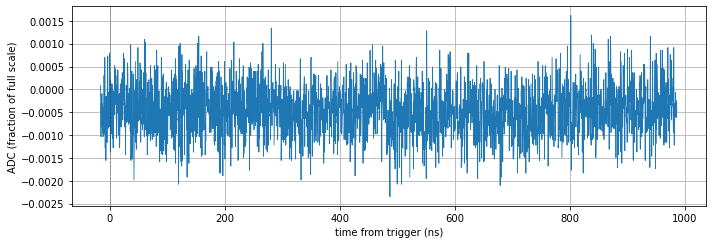

In [11]:
sc.configure(trigger="awg2", pre_ns=10, length_ns=1000)
t, y = sc.acquire(timeout=60)
print(sc.last, y.std(), y.min(), y.max())
t, y = sc.acquire(); sc.plot(t, y)

True 0.012400340500921732


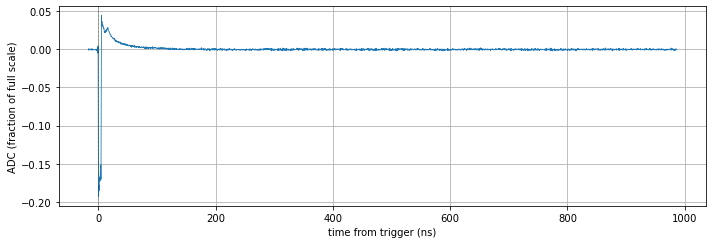

In [20]:
sc.configure(trigger="falling", level=-0.05, pre_ns=10, length_ns=1000)
t, y = sc.acquire(timeout=60)
print(sc.last["triggered"], y.std())
t, y = sc.acquire(); 
sc.plot(t, y)

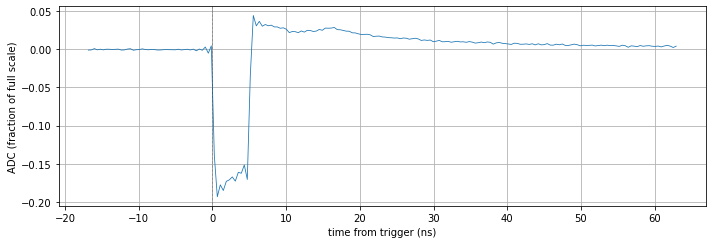

In [21]:
sc.plot(t[:int(round(20 * ns * DAC_SR))], y[:int(round(20 * ns * DAC_SR))])

# Quick accesses

In [8]:
awg.stop()

Stopped.


In [65]:
awg.play()       # = stop -> upload -> start

Stopped.
DMA upload took 0.0115 s
Started: ['DAC_A', 'DAC_B']


/home/xilinx/jupyter_notebooks/OurAWG/ADC_AWG/rfsoc_awg.py:567: UserWarning: DAC_B slot 0: peak 1.000 V exceeds the DAC full scale (+-0.250 V, -2.04 dBm). Clipping!
  warnings.warn(f"{label}: peak {np.max(np.abs(volts)):.3f} V exceeds the DAC "
/home/xilinx/jupyter_notebooks/OurAWG/ADC_AWG/rfsoc_awg.py:567: UserWarning: DAC_B slot 1: peak 1.000 V exceeds the DAC full scale (+-0.250 V, -2.04 dBm). Clipping!
  warnings.warn(f"{label}: peak {np.max(np.abs(volts)):.3f} V exceeds the DAC "
/home/xilinx/jupyter_notebooks/OurAWG/ADC_AWG/rfsoc_awg.py:567: UserWarning: DAC_A slot 0: peak 1.000 V exceeds the DAC full scale (+-0.250 V, -2.04 dBm). Clipping!
  warnings.warn(f"{label}: peak {np.max(np.abs(volts)):.3f} V exceeds the DAC "
/home/xilinx/jupyter_notebooks/OurAWG/ADC_AWG/rfsoc_awg.py:567: UserWarning: DAC_A slot 1: peak 1.000 V exceeds the DAC full scale (+-0.250 V, -2.04 dBm). Clipping!
  warnings.warn(f"{label}: peak {np.max(np.abs(volts)):.3f} V exceeds the DAC "


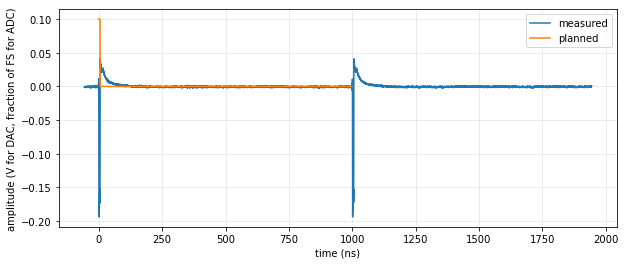

In [8]:
plt.figure(figsize=(10, 4))
plt.plot(t, y, label="measured")
plt.plot(awg.t * 1e9, SquarePulse5ns, label="planned")   # awg.t is in seconds -> ns
plt.xlabel("time (ns)")
plt.ylabel("amplitude (V for DAC, fraction of FS for ADC)")
plt.legend()
plt.grid(alpha=.3)
plt.show()

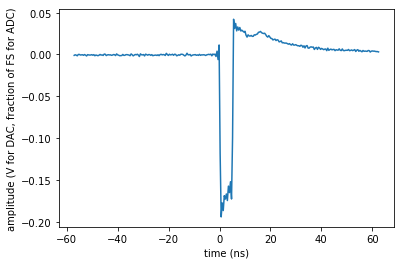

In [10]:
plt.plot(t[:int(round(30 * ns * DAC_SR))], y[:int(round(30 * ns * DAC_SR))], label="measured")
plt.xlabel("time (ns)")
plt.ylabel("amplitude (V for DAC, fraction of FS for ADC)")
plt.show()

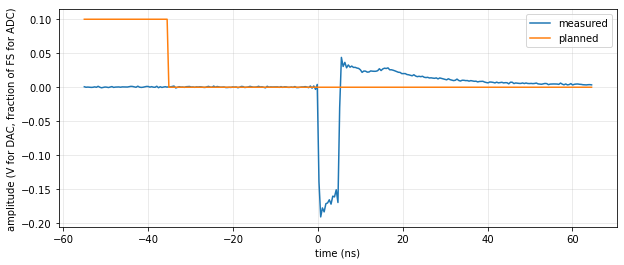

In [ ]:
plt.figure(figsize=(10, 4))
plt.plot(t[:int(round(30 * ns * DAC_SR))], y[:int(round(30 * ns * DAC_SR))], label="measured")
plt.plot(t[:int(round(30 * ns * DAC_SR))], SquarePulse5ns[:int(round(30 * ns * DAC_SR))], label="planned")   # awg.t is in seconds -> ns


plt.xlabel("time (ns)")
plt.ylabel("amplitude (V for DAC, fraction of FS for ADC)")
plt.legend()
plt.grid(alpha=.3)
plt.show()